Opening some files to look at them

In [18]:
%matplotlib ipympl

In [19]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = [8, 5]

In [20]:
reductionNo = "01"
integration = 0
n1 = fits.open("../../../../../data/uncals/jw05022001001_04102_00001-seg001_nrs1_1_rampfitstep.fits")
n2 = fits.open("../../../../../data/uncals/jw05022001001_04102_00001-seg001_nrs1_1overfstep.fits")

In [21]:
n1.info()

Filename: ../../../../../data/uncals/jw05022001001_04102_00001-seg001_nrs1_1_rampfitstep.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     220   ()      
  1  SCI           1 ImageHDU        63   (512, 32, 5160)   float32   
  2  ERR           1 ImageHDU        11   (512, 32, 5160)   float32   
  3  DQ            1 ImageHDU        12   (512, 32, 5160)   int32 (rescales to uint32)   
  4  INT_TIMES     1 BinTableHDU     24   5160R x 7C   [J, D, D, D, D, D, D]   
  5  VAR_POISSON    1 ImageHDU        10   (512, 32, 5160)   float32   
  6  VAR_RNOISE    1 ImageHDU        10   (512, 32, 5160)   float32   
  7  ASDF          1 BinTableHDU     11   1R x 1C   [20439B]   


NaN contamination: 0.62 %


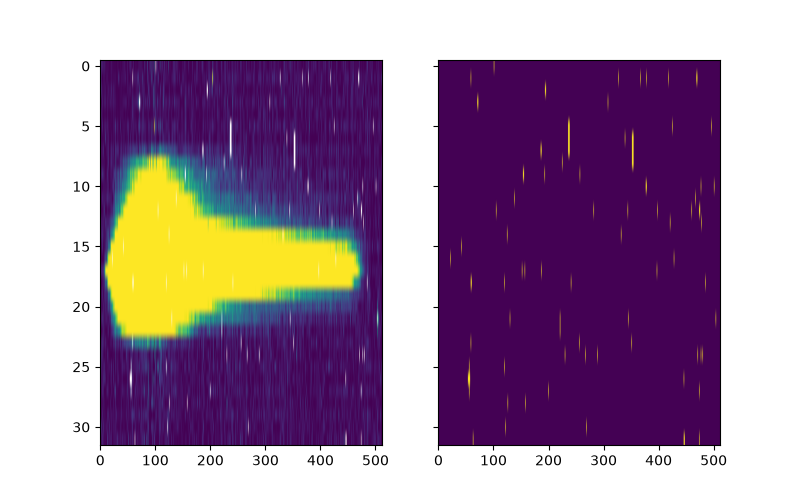

In [23]:
# NaN values are introduced in the ramp fit step, see https://jwst-docs.stsci.edu/jwst-science-calibration-pipeline/tips-and-tricks-for-working-with-the-jwst-pipeline
# Setting suppress_one_group = False does not appear to help
data = n1["SCI"].data[integration]
nan_mask = np.isnan(n1["SCI"].data[integration])
print("NaN contamination:", round( np.sum(np.isnan(data))/(n1["SCI"].shape[-1]*n1["SCI"].shape[-2]*0.01) ,2) ,"%")

fig, (ax1, ax2) = plt.subplots(1, 2, sharex=True, sharey=True)
ax1.imshow(data,aspect="auto",vmin=np.nanpercentile(data,20),vmax=np.nanpercentile(data,80))

# Plotting a DQ flag of your choice from the menu at table 3 on https://jwst-pipeline.readthedocs.io/en/latest/jwst/references_general/references_general.html
dq_val = 1
ax2.imshow(n2["PIXELDQ"].data & dq_val ,aspect="auto",vmin=0, vmax=1) # Input DQ
#ax2.imshow(n1["DQ"].data[integration] & dq_val ,aspect="auto",vmin=0, vmax=1) # Output DQ
plt.show()

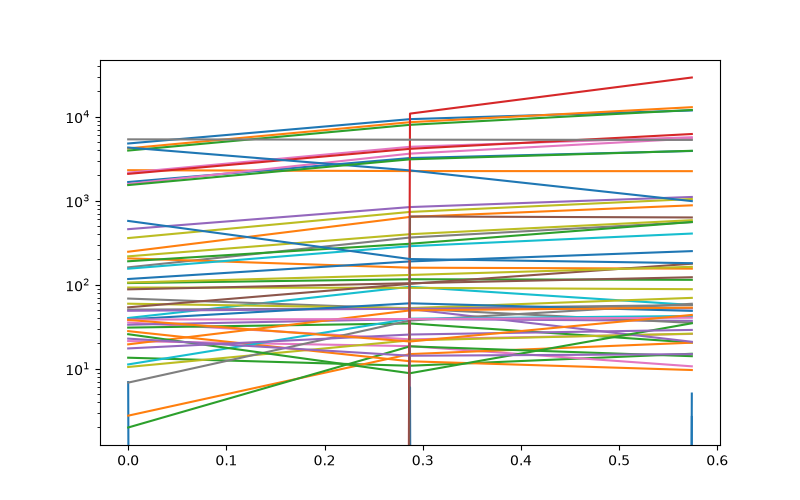

In [27]:
new_data = n1["SCI"].data[integration].astype(np.float32)

plt.figure()
for (x,y),val in np.ndenumerate(nan_mask):
    if val==True:
        times = (60*60*24)*np.linspace(0, n2["INT_TIMES"].data[integration][3]-n2["INT_TIMES"].data[integration][1], num=n2["SCI"].data.shape[1])

        # Saturation check
        unsaturated = n2["GROUPDQ"].data[integration,:,0,101] & 2 == 0

        # World's messiest plot [citation required] 
        plt.plot(times[unsaturated], n2["SCI"].data[integration,:,x,y][unsaturated], label=str(x)+" "+str(y))
        plt.yscale('log')
        
        # Below needs to be replaced after understanding https://stcal.readthedocs.io/en/latest/stcal/ramp_fitting/description.html#ramp-output-products
        new_data[x,y] = np.polyfit(times[unsaturated] ,n2["SCI"].data[integration,:,x,y][unsaturated], 1)[0].astype(np.float32)
# plt.legend()
plt.show()

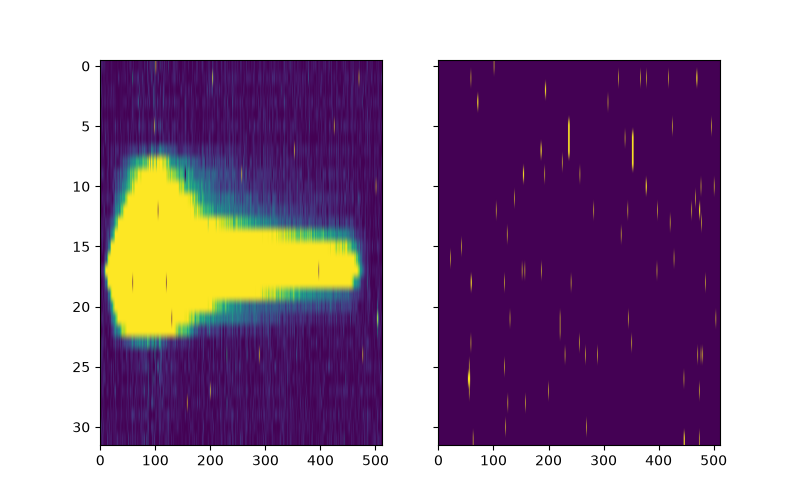

In [28]:
# Let's take a look and see if that helped!
fig, (ax1, ax2) = plt.subplots(1, 2, sharex=True, sharey=True)
ax1.imshow(new_data,aspect="auto",vmin=np.nanpercentile(data,20),vmax=np.nanpercentile(data,80))
ax2.imshow(nan_mask,aspect="auto")
plt.show()

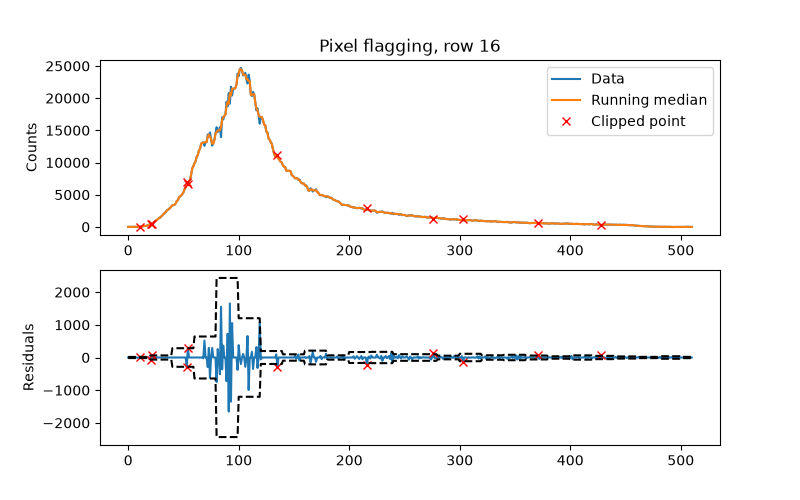

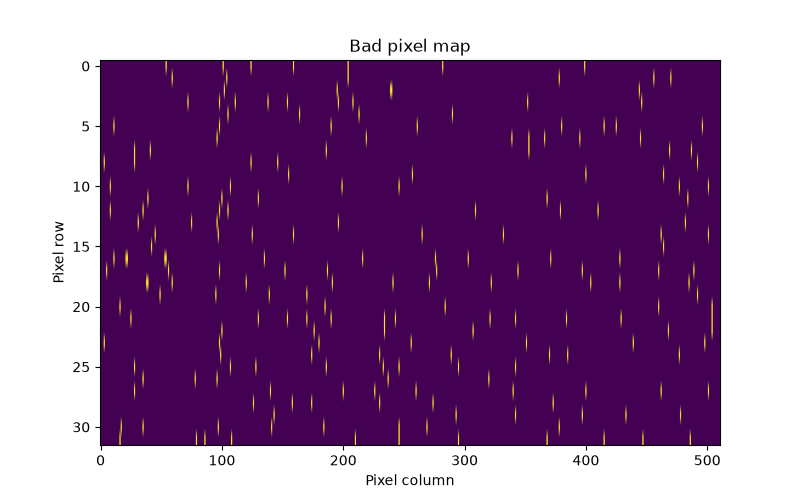

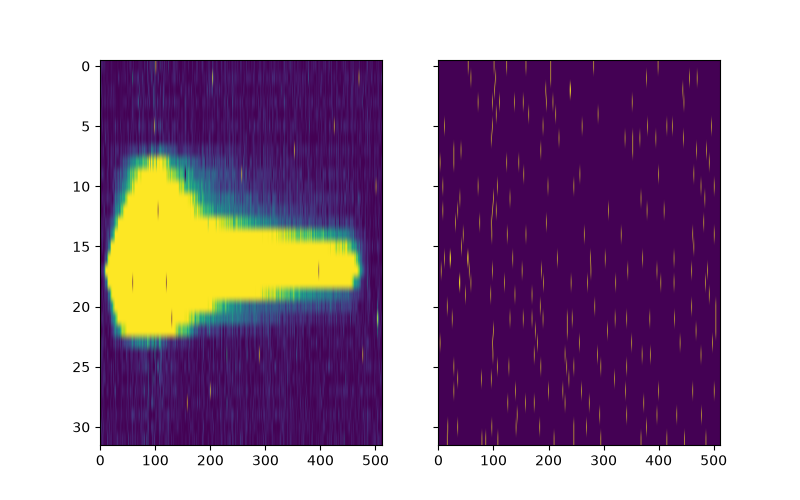

In [34]:
# Looks better but there's still some pixels that are wildly different from their neighbours. Let's see if we can identify them
from scipy.signal import medfilt
from astropy.stats import median_absolute_deviation
from reduction_utils import cosmic_removal as c

mf_box_width = 3
median = np.array([medfilt(row,mf_box_width) for row in new_data])
residuals = median - new_data

n1_mask = c.flag_bad_pixels(new_data,verbose=True,plot_rows=range(16,17),std_box_width=20,mf_box_width=mf_box_width,cut_off=3,use_mad=False,max_pixels_per_row = 20)

fig, (ax1, ax2) = plt.subplots(1, 2, sharex=True, sharey=True)
ax1.imshow(new_data,aspect="auto",vmin=np.nanpercentile(data,20),vmax=np.nanpercentile(data,80))
ax2.imshow(n1_mask,aspect="auto")
plt.show()

OK, this pixel map looks to have done a decent job. This is the first time whereby I calculated the standard deviation across the full image residuals, not row-by-row which I think helped flag additional bad pixels.

In [12]:
#pickle.dump(n1_mask,open(f"../../../../../data/reduction{reductionNo}/nircam_bad_pixel_mask.pickle","wb"))

In [31]:
help(c.flag_bad_pixels)

Help on function flag_bad_pixels in module reduction_utils.cosmic_removal:

flag_bad_pixels(
    frame,
    cut_off=5,
    max_pixels_per_row=10,
    plot_rows=None,
    use_mad=False,
    verbose=False,
    mf_box_width=3,
    left_col=0,
    right_col=-1,
    axis=None,
    std_box_width=0,
    use_gaussian_filter=False,
    existing_pixel_mask=None
)
    A function that performs a row-by-row running median to locate bad pixels in a given frame.

    Inputs:
    frame - the (nrows,ncols) frame of image data under consideration
    cut_off - the sigma/mad clip at which outliers are flagged. Default=5 (5 sigma)
    max_pixels_per_row - the maximum number of bad pixels in a row to consider. If the number of flagged pixels is greater than this number, it's assumed something went wrong and no pixels are flagged for this row. Default=10
    plot_rows - give a list of rows at which the running median will be plotted. If not given, then no running median will be plotted. Default=None.
    us

In [13]:
n1_mask.shape

(32, 512)

In [14]:
n1.info()

Filename: ../../../../../data/uncals/jw05022001001_04102_00001-seg001_nrs1_uncal.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     203   ()      
  1  SCI           1 ImageHDU        67   (512, 32, 5, 5160)   uint16   
  2  GROUP         1 BinTableHDU     38   1720R x 13C   [J, I, I, J, I, 26A, I, I, I, I, 36A, D, D]   
  3  INT_TIMES     1 BinTableHDU     24   5160R x 7C   [J, D, D, D, D, D, D]   
  4  ASDF          1 BinTableHDU     11   1R x 1C   [8346B]   


In [15]:
def save_new_fits(data,filename,original_header):
    # copy original header to new header
    new_header = original_header

    # make science extension
    hdu1 = fits.PrimaryHDU([data],header=new_header) # science array
    hdu1.name = "SCI"

    # make dummy error extension
    hdu2 = fits.ImageHDU(np.zeros_like([data]))
    hdu2.name = "ERR"

    # make dummy integration extension
    c3 = fits.Column(name='int_mid_BJD_TDB', array=np.array([0.]), format='K')
    hdu3 = fits.BinTableHDU.from_columns([c3])
    hdu3.name = "INT_TIMES"

    hdu = fits.HDUList([hdu1,hdu2,hdu3])
    print("saving %s"%filename)
    hdu.writeto(filename,overwrite=True)
    return hdu

In [16]:
master_uncal_n1 = save_new_fits(n1_science_masked,f"../../../../../data/reduction{reductionNo}/master_uncal.fits",n1[0].header) 

saving ../../../../../data/reduction01/master_uncal.fits


In [17]:
n1_science_masked.shape

(32, 512)

### Quick look white light curves

In [24]:
r01 = np.loadtxt("reduction01/white_light.dat")
r02 = np.loadtxt("reduction02/white_light.dat")
r03 = np.loadtxt("reduction03/white_light.dat")

from scipy.ndimage import gaussian_filter

<IPython.core.display.Javascript object>


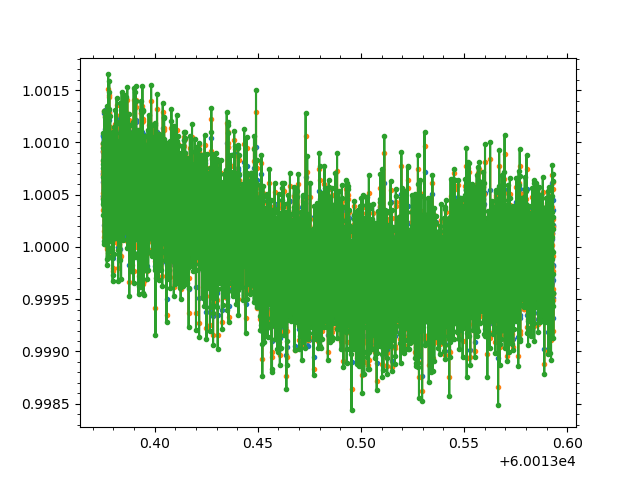

In [26]:
plt.figure()
plt.plot(r01[:,0],r01[:,1]/r01[:,1].mean(),label="reduction01",marker='.')
plt.plot(r02[:,0],r02[:,1]/r02[:,1].mean(),label="reduction02",marker='.')
plt.plot(r03[:,0],r03[:,1]/r03[:,1].mean(),label="reduction03",marker='.')
plt.show()

<IPython.core.display.Javascript object>


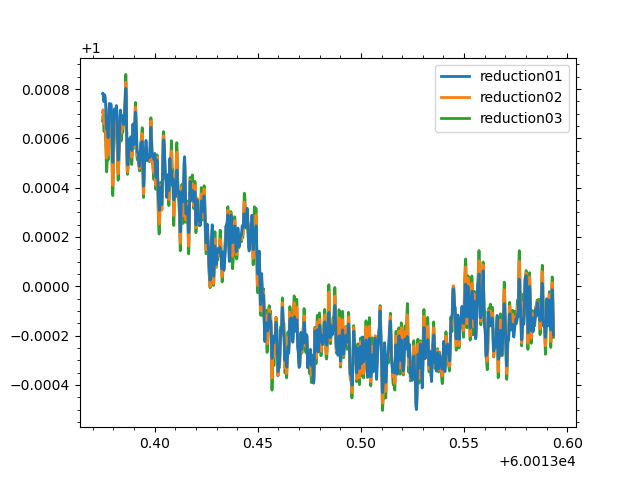

In [37]:
plt.figure()
# plt.plot(r01[:,0],r01[:,1]/r01[:,1].mean(),label="reduction01",marker='.',ls="None")
plt.plot(r01[:,0],gaussian_filter(r01[:,1]/r01[:,1].mean(),sigma=5),label="reduction01",lw=2,zorder=3)
plt.plot(r02[:,0],gaussian_filter(r02[:,1]/r02[:,1].mean(),sigma=5),label="reduction02",lw=2,zorder=2)
plt.plot(r03[:,0],gaussian_filter(r03[:,1]/r03[:,1].mean(),sigma=5),label="reduction03",lw=2,zorder=1)
plt.legend()
# plt.plot(r02[:,0],r02[:,1]/r02[:,1].mean(),label="reduction02",marker='.')
# plt.plot(r03[:,0],r03[:,1]/r03[:,1].mean(),label="reduction03",marker='.')
plt.show()

OK so all reductions give the same red noise but the lowest amplitude is with the narrower ap so this is the way to go, at least with these background assumptions

<IPython.core.display.Javascript object>


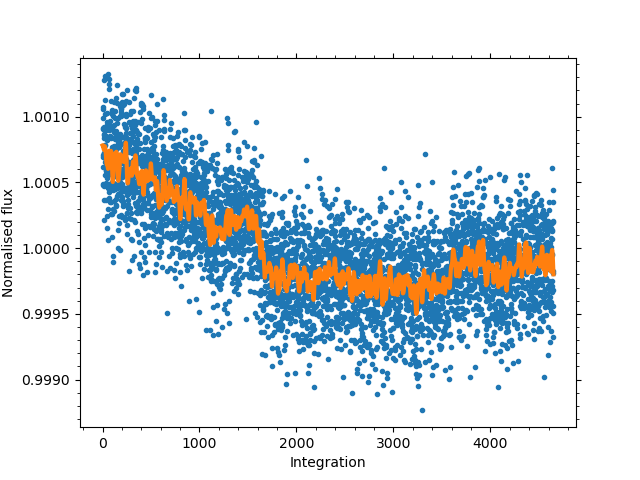

In [41]:
plt.figure()
plt.plot(r01[:,1]/r01[:,1].mean(),label="reduction01",marker='.',ls="None")
plt.plot(gaussian_filter(r01[:,1]/r01[:,1].mean(),sigma=5),label="reduction01",lw=3,zorder=3)
plt.xlabel("Integration")
plt.ylabel("Normalised flux")
plt.show()

In [43]:
r01[:,0]

array([60013.374709, 60013.374756, 60013.374803, ..., 60013.593228,
       60013.593275, 60013.593322])